# Матричная факторизация и быстрый поиск рекомендаций

В прошлой практике мы строили рекомендации на основе сходства пользователей или объектов и обучаемых связей между объектами: user/item kNN, SLIM, EASE. Теперь попробуем другой подход — **матричную факторизацию (Matrix Factorization, MF)**: представим пользователей и объекты компактными векторами в общем пространстве скрытых факторов.

Пусть $R$ — матрица взаимодействий: строки соответствуют пользователям, столбцы — объектам, а $r_{ui}$ — вес взаимодействия пользователя $u$ с объектом $i$. Хотим приблизить её произведением двух матриц:

$$
R \approx PQ^\top
$$

<center><img width='500px' src='images/practice-3/matrix-factorization.png'></center>

Здесь $P\in\mathbb{R}^{n_{users}\times d}$ содержит векторы пользователей, а $Q\in\mathbb{R}^{n_{items}\times d}$ — векторы айтемов. Каждая строка — описание одного пользователя или объекта через $d$ латентных факторов. Обычно $d$ значительно меньше числа пользователей и объектов.

Интуитивно факторы можно представить как особенности вкуса: интерес к экшену, романтике или сложным сюжетам. Но реальные факторы не обязательно имеют понятные названия и не совпадают с жанрами.

Предсказание — скалярное произведение векторов пользователя и объекта:

$$
\hat r_{ui}=p_u^\top q_i, \qquad \hat{R} = PQ^\top
$$
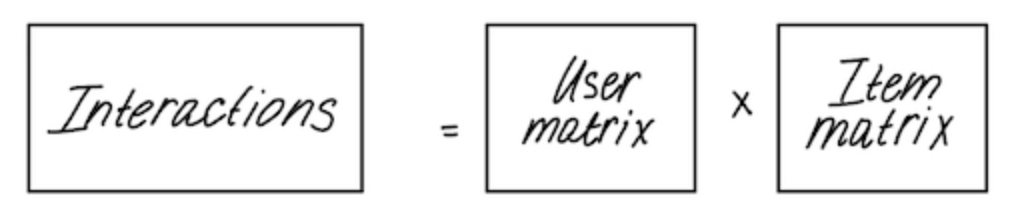

# План практики

Сначала реализуем PureSVD, FunkSVD, ALS и SVD++ на маленьких матрицах, затем перейдём к iALS, BPR-MF и Logistic MF для неявных взаимодействий. После этого сравним библиотечные PureSVD, iALS, BPR-MF и Logistic MF на KION: посмотрим, как способ обучения и число факторов влияют на рекомендации.

В последней части перейдём от обучения к выдаче. Даже с готовыми векторами нужно быстро находить лучшие объекты для пользователя. Сравним точный поиск с приближённым поиском ближайших соседей — **ANN (Approximate Nearest Neighbor)** — и разберём компромисс между скоростью и точностью поиска.


# Explicit


## PureSVD

**SVD (Singular Value Decomposition)** — разложение матрицы взаимодействий на три множителя:

$$
R=U\Sigma V^\top
$$

<center>
<img width='500px' src='images/practice-3/svd.png'>
</center>

Столбцы $U$ и $V$ задают общие скрытые факторы: $U$ описывает связь пользователей с факторами, а $V$ — объектов. Матрицы имеют ортонормированные столбцы, а диагональная $\Sigma$ содержит сингулярные значения — веса факторов. Чем больше сингулярное значение, тем больше вклад фактора в восстановление $R$.

Оставим $d$ наибольших сингулярных значений и соответствующие столбцы $U$ и $V$:

$$
R\approx U_d\Sigma_dV_d^\top=PQ^\top,
\qquad P=U_d,\quad Q=V_d\Sigma_d
$$

<center>
<img width='600px' src='images/practice-3/truncated-svd.png'>
</center>

Это **усечённое SVD**: среди всех матриц ранга не выше $d$ оно минимизирует квадратичную ошибку восстановления $R$. Вместо полной таблицы сохраняем компактные векторы пользователей и объектов.

**PureSVD** применяет такое разложение к матрице взаимодействий, включая нули на месте отсутствующих взаимодействий. Они участвуют в восстановлении наравне с наблюдаемыми значениями — модель не различает отсутствие интереса и отсутствие информации.

Ниже реализуем PureSVD самостоятельно
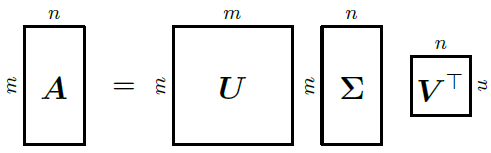
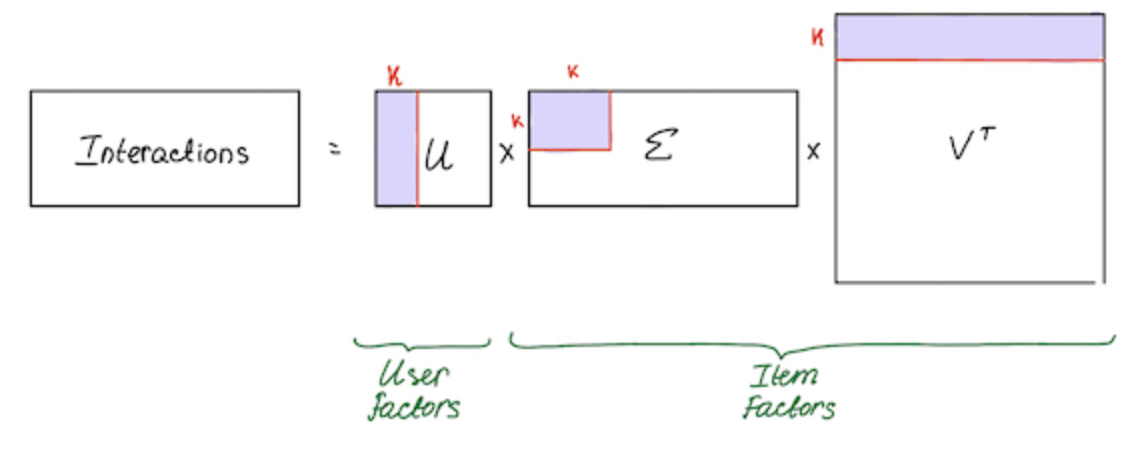

In [1]:
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

class PureSVDRecommender:
    def __init__(self, n_factors: int = 50, random_state: int | None = None):
        self.n_factors = n_factors
        self.random_state = random_state
        self.U = None            # (n_users, k)
        self.V = None            # (n_items, k)  item factors (Sigma * Vt)^T
        self.user_items = None   # sparse R for filtering seen items

    def fit(self, R: csr_matrix):

        self.user_items = R.tocsr()

        rng = np.random.default_rng(self.random_state)
        U, s, Vt = svds(self.user_items, k=self.n_factors, rng=rng)

        self.U = U
        self.V = (np.diag(s) @ Vt).T  # (n_items, k)
        return self

    def recommend(self, user_id: int, k: int = 10, filter_seen: bool = True):

        scores = self.U[user_id] @ self.V.T  # (n_items,)

        if filter_seen: # Давайте порассуждаем?
            start, end = self.user_items.indptr[user_id], self.user_items.indptr[user_id + 1]
            seen_items = self.user_items.indices[start:end]
            scores[seen_items] = -np.inf

        topk_idx = np.argpartition(scores, -k)[-k:]
        topk_idx = topk_idx[np.argsort(scores[topk_idx])[::-1]]
        return topk_idx, scores[topk_idx]

    def predict_all(self):
        return self.U @ self.V.T

    def user_vectors(self):
        return self.U

    def item_vectors(self):
        return self.V

### Маленькая матрица: обучение и выдача

Сгенерируем матрицу пяти пользователей и десяти объектов: ноль обозначает отсутствие взаимодействия, положительные числа — его вес. Оставим четыре фактора и получим три рекомендации для пользователя с внутренним ID 0.


In [2]:
np.random.seed(42)

In [3]:
m = 8   # кол-во юзеров
n = 5  # кол-во айтемов

stars = np.arange(6) # оценки 0-5

stars_weights = np.array([20, 1, 1, 1, 1, 2])  # веса для оценок 0-5 (чаще всего нули)
p = stars_weights / stars_weights.sum()        # вероятности оценок

ratings = np.random.choice(stars, size=m*n, p=p).reshape((m, n))
ratings

array([[0, 5, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 5, 2, 0, 0],
       [0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 0, 0, 5, 5],
       [2, 0, 0, 0, 0]])

In [4]:
csr_matrix(ratings)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 8 stored elements and shape (8, 5)>

In [5]:
model = PureSVDRecommender(n_factors=4, random_state=42).fit(csr_matrix(ratings))

In [6]:
model.predict_all()

array([[-3.79297467e-16,  5.00000000e+00, -5.28102765e-16,
        -1.12632782e-15, -1.12632782e-15],
       [-9.86076132e-32,  1.02841623e-16,  3.00000000e+00,
         7.67908446e-16,  7.67908446e-16],
       [-6.90253292e-31,  5.00000000e+00,  2.00000000e+00,
        -5.45770550e-16, -5.45770550e-16],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00],
       [ 1.00000000e+00,  1.90150326e-15, -2.63119829e-17,
         4.99600361e-16,  4.99600361e-16],
       [-4.00491984e-31, -5.58022909e-16,  1.91163158e-15,
         5.00000000e+00,  5.00000000e+00],
       [ 2.00000000e+00,  3.80300652e-15, -5.26239659e-17,
         9.99200722e-16,  9.99200722e-16]])

In [7]:
rec_items, rec_scores = model.recommend(user_id=0, k=3, filter_seen=True)
print("Recommended items:", rec_items)
print("Scores:", rec_scores)

Recommended items: [0 2 4]
Scores: [-3.79297467e-16 -5.28102765e-16 -1.12632782e-15]


## FunkSVD: обучаемся только на известных оценках

PureSVD восстанавливает всю матрицу, включая нули. **FunkSVD** обучает векторы только по наблюдаемым оценкам $\Omega$. Это факторизация, обучаемая градиентными обновлениями, а не прямое сингулярное разложение:

$$
\min_{P,Q}\;\sum_{(u,i)\in\Omega}(r_{ui}-p_u^\top q_i)^2
+\lambda\left(\|P\|_F^2+\|Q\|_F^2\right)
$$

Для одной известной оценки вычисляем ошибку $e_{ui}=r_{ui}-p_u^\top q_i$ и сдвигаем оба вектора в сторону её уменьшения. Используем **SGD (Stochastic Gradient Descent)**: перемешиваем известные пары и обновляем параметры по одной паре. В этой версии смещения пока не добавляем.

Задача совместно по $P$ и $Q$ невыпуклая: SGD не гарантирует нахождения глобального минимума, а результат зависит от инициализации и порядка обновлений.


### Общий пример явных оценок

Для новых моделей используем отдельную фиксированную матрицу: оценки от 1 до 5, ноль — пропуск. Маленькая демонстрация показывает обучение и восстановление; это не сравнение качества на отложенных данных. В отличие от предыдущего примера, оценки заданы вручную и воспроизводимы.


In [8]:
class FunkSVD:
    def __init__(self, factors=2, learning_rate=0.02, l2=0.1, random_state=42):
        self.factors = factors
        self.learning_rate = learning_rate
        self.l2 = l2
        self.random_state = random_state

    def fit(self, R, epochs=200):
        rng = np.random.default_rng(self.random_state)
        users, items = np.nonzero(R)  # индексы с непустыми значениями 
        self.P = rng.normal(0, 0.1, (R.shape[0], self.factors))
        self.Q = rng.normal(0, 0.1, (R.shape[1], self.factors))
        # Частоты нужны, чтобы за эпоху L2 учитывалась один раз на вектор.
        user_counts = np.bincount(users, minlength=R.shape[0])
        item_counts = np.bincount(items, minlength=R.shape[1])
        self.loss = []
        for _ in range(epochs):
            for idx in rng.permutation(len(users)):
                u, i = users[idx], items[idx]
                p, q = self.P[u].copy(), self.Q[i].copy()
                error = R[u, i] - p @ q
                self.P[u] += self.learning_rate * (
                    error * q - self.l2 * p / user_counts[u]  # аналитический градиент
                )
                self.Q[i] += self.learning_rate * (
                    error * p - self.l2 * q / item_counts[i]  # аналитический градиент
                )
            error = (R - self.predict_all())[users, items]
            penalty = self.l2 * ((self.P ** 2).sum() + (self.Q ** 2).sum())
            self.loss.append((error ** 2).sum() + penalty)
        return self

    def predict_all(self):
        return self.P @ self.Q.T

In [9]:
explicit_ratings = np.array([
    [5, 4, 0, 1, 0, 2],
    [4, 5, 0, 1, 2, 0],
    [0, 1, 5, 4, 0, 4],
    [1, 0, 4, 5, 4, 0],
    [5, 4, 1, 0, 0, 1],
    [0, 2, 4, 5, 5, 0],
], dtype=float)
observed = explicit_ratings > 0
explicit_ratings

array([[5., 4., 0., 1., 0., 2.],
       [4., 5., 0., 1., 2., 0.],
       [0., 1., 5., 4., 0., 4.],
       [1., 0., 4., 5., 4., 0.],
       [5., 4., 1., 0., 0., 1.],
       [0., 2., 4., 5., 5., 0.]])

In [10]:
funk_svd = FunkSVD().fit(explicit_ratings)
print(f"Начальный loss: {funk_svd.loss[0]:.3f}")
print(f"Конечный loss: {funk_svd.loss[-1]:.3f}")
np.round(funk_svd.predict_all(), 2)

Начальный loss: 320.944
Конечный loss: 8.203


array([[ 4.72,  4.27,  1.65,  1.23,  2.47,  1.8 ],
       [ 4.63,  4.31,  1.25,  0.77,  2.07,  1.44],
       [ 2.43,  1.08,  4.26,  4.57,  4.46,  3.96],
       [ 0.97, -0.38,  4.16,  4.66,  4.08,  3.76],
       [ 4.58,  4.35,  0.97,  0.46,  1.8 ,  1.19],
       [ 3.36,  1.96,  4.43,  4.64,  4.81,  4.18]])

## ALS — другой способ оптимизации

Вместо SGD можно минимизировать ту же функцию потерь **чередующимися наименьшими квадратами (ALS)**. При фиксированных векторах объектов каждый пользователь решает отдельную задачу линейной регрессии, затем аналогично обновляются объекты:

$$
p_u=(Q_{I_u}^\top Q_{I_u}+\lambda I_d)^{-1}Q_{I_u}^\top r_{u,I_u},
\qquad
q_i=(P_{U_i}^\top P_{U_i}+\lambda I_d)^{-1}P_{U_i}^\top r_{U_i,i}
$$

$I_u$ — объекты с известными оценками пользователя, $U_i$ — пользователи, оценившие объект. Нулевые пропуски в эти задачи не входят. ALS — способ оптимизации факторизации; здесь он работает с явными оценками, а iALS ниже — с неявными предпочтениями и уверенностями.


In [11]:
class ExplicitALS:
    def __init__(self, factors=2, l2=0.1, random_state=42):
        self.factors = factors
        self.l2 = l2
        self.random_state = random_state

    def fit(self, R, epochs=30):
        rng = np.random.default_rng(self.random_state)
        self.P = rng.normal(0, 0.1, (R.shape[0], self.factors))
        self.Q = rng.normal(0, 0.1, (R.shape[1], self.factors))
        mask = R > 0
        regularizer = self.l2 * np.eye(self.factors)
        self.loss = []
        for _ in range(epochs):
            for u in range(R.shape[0]):
                known = mask[u]
                Q_known = self.Q[known]
                self.P[u] = np.linalg.solve(  # аналитическая формула, но реализованная через .solve() - эффективнее
                    Q_known.T @ Q_known + regularizer,
                    Q_known.T @ R[u, known],
                )
            for i in range(R.shape[1]):
                known = mask[:, i]
                P_known = self.P[known]
                self.Q[i] = np.linalg.solve(  # аналитическая формула, но реализованная через .solve() - эффективнее
                    P_known.T @ P_known + regularizer,
                    P_known.T @ R[known, i],
                )
            error = (R - self.predict_all())[mask]
            penalty = self.l2 * ((self.P ** 2).sum() + (self.Q ** 2).sum())
            self.loss.append((error ** 2).sum() + penalty)
        return self

    def predict_all(self):
        return self.P @ self.Q.T

In [12]:
explicit_ratings

array([[5., 4., 0., 1., 0., 2.],
       [4., 5., 0., 1., 2., 0.],
       [0., 1., 5., 4., 0., 4.],
       [1., 0., 4., 5., 4., 0.],
       [5., 4., 1., 0., 0., 1.],
       [0., 2., 4., 5., 5., 0.]])

In [13]:
explicit_als = ExplicitALS().fit(explicit_ratings, epochs=100)
print(f"Начальный loss: {explicit_als.loss[0]:.3f}")
print(f"Конечный loss: {explicit_als.loss[-1]:.3f}")
np.round(explicit_als.predict_all(), 2)

Начальный loss: 57.351
Конечный loss: 8.176


array([[ 4.75,  4.21,  1.64,  1.29,  2.53,  1.76],
       [ 4.59,  4.35,  1.1 ,  0.68,  2.01,  1.29],
       [ 3.32,  1.06,  4.3 ,  4.57,  4.62,  3.96],
       [ 1.01, -1.39,  4.18,  4.73,  4.  ,  3.69],
       [ 4.54,  4.34,  1.03,  0.61,  1.93,  1.22],
       [ 4.19,  1.94,  4.42,  4.59,  4.92,  4.13]])

### Сравним оптимизацию

Обе реализации минимизируют одну функцию потерь с одинаковой L2-регуляризацией. Для SGD вклад регуляризации распределён по обновлениям каждого вектора. ALS решает условные задачи точно, SGD делает небольшие шаги; число эпох этих алгоритмов не равноценная мера вычислений. Совместная задача невыпуклая, поэтому результаты могут различаться.

Ниже считаем RMSE только на известных **обучающих** оценках. Сравнение показывает подгонку данных, а не способность предсказывать новые оценки.


In [14]:
def observed_rmse(R, predictions):
    mask = R > 0
    return np.sqrt(np.mean((R[mask] - predictions[mask]) ** 2))


for name, fitted_model in [("FunkSVD (SGD)", funk_svd), ("Explicit ALS", explicit_als)]:
    rmse = observed_rmse(explicit_ratings, fitted_model.predict_all())
    print(f"{name}: train RMSE = {rmse:.3f}")

FunkSVD (SGD): train RMSE = 0.347
Explicit ALS: train RMSE = 0.339


# Explicit + Implicit / Implicit


## SVD++: дополняем пользователя его историей

**SVD++** расширяет факторную модель явных оценок: учитывает не только персональный вектор, но и набор объектов, с которыми пользователь взаимодействовал. Добавим среднюю оценку $\mu$, смещения $b_u,b_i$ и векторы истории $y_j$:

$$
\widetilde p_u=p_u+\frac{1}{\sqrt{|H_u|}}\sum_{j\in H_u}y_j,
\qquad
\hat r_{ui}=\mu+b_u+b_i+q_i^\top\widetilde p_u
$$

$H_u$ — известная история пользователя. У объекта два вектора: $q_i$ описывает его как кандидата, $y_j$ — его вклад в представление пользователя. Сумма использует факт взаимодействия, независимо от значения оценки. В нашем примере история — набор объектов с известными обучающими оценками, целевой объект тоже может входить в неё. Для пустой истории вклад суммы считаем нулевым.

Обучаемся по известным оценкам с регуляризацией:

$$
\min_{P,Q,Y,b}\;\sum_{(u,i)\in\Omega}(r_{ui}-\hat r_{ui})^2
+\lambda\left(\|P\|_F^2+\|Q\|_F^2+\|Y\|_F^2+\|b^U\|_2^2+\|b^I\|_2^2\right)
$$

Ниже для прозрачности используем **пакетный градиентный спуск**: сначала считаем все градиенты, затем обновляем параметры. Учебная реализация проходит по всей истории для каждой оценки и рассчитана на маленький пример.

In [15]:
class SVDPlusPlus:
    def __init__(self, factors=2, learning_rate=0.01, l2=0.1, random_state=42):
        self.factors = factors
        self.learning_rate = learning_rate
        self.l2 = l2
        self.random_state = random_state

    def fit(self, R, epochs=400):
        rng = np.random.default_rng(self.random_state)
        users, items = np.nonzero(R)
        self.mean = R[users, items].mean()
        self.P = rng.normal(0, 0.1, (R.shape[0], self.factors))
        self.Q = rng.normal(0, 0.1, (R.shape[1], self.factors))
        self.Y = rng.normal(0, 0.1, (R.shape[1], self.factors))
        self.bu = np.zeros(R.shape[0])
        self.bi = np.zeros(R.shape[1])
        self.history = [np.flatnonzero(row > 0) for row in R]
        self.loss = []
        for _ in range(epochs):
            effective_users = self.user_vectors()
            # Градиенты половины loss: общий множитель 2 поглощён шагом.
            dP, dQ, dY = self.l2 * self.P, self.l2 * self.Q, self.l2 * self.Y
            dbu, dbi = self.l2 * self.bu, self.l2 * self.bi
            for u, i in zip(users, items):
                prediction = self.mean + self.bu[u] + self.bi[i] + effective_users[u] @ self.Q[i]
                error = R[u, i] - prediction
                dP[u] -= error * self.Q[i]
                dQ[i] -= error * effective_users[u]
                dbu[u] -= error
                dbi[i] -= error
                history = self.history[u]
                if len(history):
                    dY[history] -= error * self.Q[i] / np.sqrt(len(history))
            for parameter, gradient in zip(
                [self.P, self.Q, self.Y, self.bu, self.bi],
                [dP, dQ, dY, dbu, dbi],
            ):
                parameter -= self.learning_rate * gradient
            error = (R - self.predict_all())[users, items]
            penalty = self.l2 * sum(
                (parameter ** 2).sum()
                for parameter in [self.P, self.Q, self.Y, self.bu, self.bi]
            )
            self.loss.append((error ** 2).sum() + penalty)
        return self

    def user_vectors(self):
        effective_users = self.P.copy()
        for u, history in enumerate(self.history):
            if len(history):
                effective_users[u] += self.Y[history].sum(axis=0) / np.sqrt(len(history))
        return effective_users

    def predict_all(self):
        return (
            self.mean + self.bu[:, None] + self.bi[None, :]
            + self.user_vectors() @ self.Q.T
        )

In [16]:
explicit_ratings

array([[5., 4., 0., 1., 0., 2.],
       [4., 5., 0., 1., 2., 0.],
       [0., 1., 5., 4., 0., 4.],
       [1., 0., 4., 5., 4., 0.],
       [5., 4., 1., 0., 0., 1.],
       [0., 2., 4., 5., 5., 0.]])

In [17]:
svd_plus_plus = SVDPlusPlus().fit(explicit_ratings)
print(f"Начальный loss: {svd_plus_plus.loss[0]:.3f}")
print(f"Конечный loss: {svd_plus_plus.loss[-1]:.3f}")
print(f"Train RMSE: {observed_rmse(explicit_ratings, svd_plus_plus.predict_all()):.3f}")
np.round(svd_plus_plus.predict_all(), 2)

Начальный loss: 60.427
Конечный loss: 2.199
Train RMSE: 0.102


array([[ 4.95,  4.02,  2.1 ,  1.  ,  2.44,  2.02],
       [ 4.06,  4.92,  0.62,  1.03,  2.06,  1.58],
       [ 3.09,  1.02,  4.91,  4.05,  4.33,  3.98],
       [ 1.02,  0.53,  3.93,  4.86,  4.23,  3.85],
       [ 4.95,  4.03,  1.06, -0.33,  1.46,  1.03],
       [ 2.28,  2.07,  4.16,  5.07,  4.68,  4.28]])

## iALS: учитываем уверенность во взаимодействиях

**iALS (Implicit Alternating Least Squares)** разделяет факт предпочтения и уверенность в нём. Сначала разберём алгоритм на маленькой матрице, затем применим библиотечную модель к KION.

In [18]:
import pandas as pd
import matplotlib_inline
import seaborn as sns

np.random.seed(32)
sns.set_theme(style="dark")
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

### Предпочтения и уверенность

Из матрицы взаимодействий $R$ получаем бинарное предпочтение $\phi$ и уверенность $C$:

$$
\phi_{ui}=\mathbb{1}[r_{ui}>0],\qquad c_{ui}=1+\alpha r_{ui}
$$

Если взаимодействия нет, целевое значение равно 0, а уверенность — 1. Если оно есть, целевое значение равно 1, а уверенность растёт с весом взаимодействия. Коэффициент $\alpha$ управляет этим ростом. Матрицы $P$ и $Q$ по-прежнему содержат векторы пользователей и объектов.


### Функция потерь

$$
\min_{P,Q}\;\sum_{u,i}c_{ui}(\phi_{ui}-p_u^\top q_i)^2
+\lambda\left(\|P\|_F^2+\|Q\|_F^2\right)
$$

Сумма берётся по всем парам пользователей и объектов, включая отсутствующие взаимодействия. Ошибка на паре с высокой уверенностью имеет больший вес. L2-регуляризация с коэффициентом $\lambda$ ограничивает величину векторов.


### Чередование обновлений

Поочерёдно обновляем векторы объектов при фиксированных пользователях и векторы пользователей при фиксированных объектах:

$$
\begin{aligned}
p_u&=\left(Q^\top Q+Q^\top(C_u-I)Q+\lambda I\right)^{-1}Q^\top C_u\phi_u,\\
q_i&=\left(P^\top P+P^\top(C_i-I)P+\lambda I\right)^{-1}P^\top C_i\phi_i.
\end{aligned}
$$

$C_u$ — диагональная матрица уверенностей пользователя по всем объектам, $C_i$ — уверенностей для объекта по всем пользователям. Векторы $\phi_u$ и $\phi_i$ содержат соответствующие предпочтения; $I$ — единичная матрица нужного размера.


### Реализация с нуля

In [19]:
class ImplicitALS:

    def __init__(self, R, k=3, a=40, l2=10):
      self.l2 = l2
      self.k = k # number of latent factors
      self.a = a # confidence scaling factor
      self.n_users, self.n_items = R.shape

      # Initialize latent factors
      self.P = np.random.rand(self.n_users, self.k) # user latent factors n x k
      self.Q = np.random.rand(self.n_items, self.k) # item latent factors m x k

      self.phi = np.where(R > 0, 1, 0)
      self.C = 1 + a * R # CODE

      self.loss = []

    def fit(self, n_step=10):

        for _ in range(n_step):

            # fix P, update Q
            PtP = self.P.T @ self.P
            for i in range(self.n_items):
                Ci = np.diag(self.C[:, i])
                Wi = PtP + self.P.T @ (Ci - np.identity(self.n_users)) @ self.P + self.l2 * np.identity(self.k)
                self.Q[i] =  np.linalg.inv(Wi) @ self.P.T @ Ci @ self.phi[:, i]

            # fix Q, update P
            QtQ = self.Q.T @ self.Q
            for u in range(self.n_users):
                Cu = np.diag(self.C[u, :])
                Wu = QtQ + self.Q.T @ (Cu - np.identity(self.n_items)) @ self.Q + self.l2 * np.identity(self.k)
                self.P[u] =  np.linalg.inv(Wu) @ self.Q.T @ Cu @ self.phi[u, :]

            # Compute LOSS
            predictions = self.P @ self.Q.T
            loss = (self.C * (self.phi - predictions) ** 2).sum()
            l2_all = (self.P ** 2).sum() + (self.Q ** 2).sum()
            loss_with_l2_reg = loss + self.l2*l2_all
            self.loss.append(loss_with_l2_reg)

    def predict(self, u, i):
        return self.P[u] @ self.Q[i]

    def predict_all(self):
        return self.P @ self.Q.T

In [20]:
implicit_ratings = explicit_ratings.copy()

In [21]:
als = ImplicitALS(R=implicit_ratings, k=16)
als.fit(n_step=50)

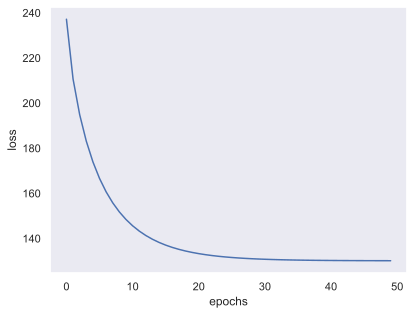

In [22]:
ax = sns.lineplot(als.loss)
ax.set_xlabel("epochs")
ax.set_ylabel("loss");

In [23]:
implicit_ratings

array([[5., 4., 0., 1., 0., 2.],
       [4., 5., 0., 1., 2., 0.],
       [0., 1., 5., 4., 0., 4.],
       [1., 0., 4., 5., 4., 0.],
       [5., 4., 1., 0., 0., 1.],
       [0., 2., 4., 5., 5., 0.]])

In [24]:
als.predict_all().round(4)

array([[0.981 , 0.9818, 0.9658, 0.9703, 0.9569, 0.9488],
       [0.9785, 0.9798, 0.9666, 0.9712, 0.9593, 0.9457],
       [0.9944, 0.9956, 0.9813, 0.9858, 0.9732, 0.9614],
       [0.986 , 0.9878, 0.9776, 0.9823, 0.972 , 0.9523],
       [0.9769, 0.9778, 0.9622, 0.9666, 0.9534, 0.9448],
       [0.9883, 0.99  , 0.9799, 0.9846, 0.9744, 0.9545]])

## BPR-MF: обучаем порядок объектов

**BPR (Bayesian Personalized Ranking)** — функция потерь для парного ранжирования. Применим её к матричной факторизации: для пользователя $u$ оценка объекта с взаимодействием $i$ должна быть выше оценки объекта без взаимодействия $j$.

$$
\Delta_{uij}=p_u^\top(q_i-q_j),\qquad
\mathcal L=-\frac{1}{|D|}\sum_{(u,i,j)\in D}\log\sigma(\Delta_{uij})
+\frac{\lambda}{2}\left(\|P\|_F^2+\|Q\|_F^2\right)
$$

$D$ — обучающие тройки, $\sigma(z)=1/(1+e^{-z})$. Если положительный объект выше отрицательного с большим отрывом, потеря мала. Величины исходных оценок больше не используем: важен факт взаимодействия.

Для маленькой матрицы переберём все допустимые тройки и применим пакетный градиентный спуск. В больших датасетах тройки обычно сэмплируют. Ненаблюдаемый объект здесь служит отрицательным примером, но не обязательно неинтересен пользователю.

Обычно векторы пользователей и объектов обучаются совместно — задача невыпуклая. В отличие от ALS, здесь нет чередующегося решения задач при фиксированной второй матрице.

Источник: [BPR: Bayesian Personalized Ranking from Implicit Feedback](https://arxiv.org/abs/1205.2618).

In [25]:
# оставляем только факт взаимодействия.
binary_ratings = (implicit_ratings > 0).astype(float)
binary_ratings

array([[1., 1., 0., 1., 0., 1.],
       [1., 1., 0., 1., 1., 0.],
       [0., 1., 1., 1., 0., 1.],
       [1., 0., 1., 1., 1., 0.],
       [1., 1., 1., 0., 0., 1.],
       [0., 1., 1., 1., 1., 0.]])

In [26]:
class BPRMF:
    def __init__(self, factors=2, learning_rate=0.5, l2=0.01, random_state=42):
        self.factors = factors
        self.learning_rate = learning_rate
        self.l2 = l2
        self.random_state = random_state

    def fit(self, R, epochs=300):
        rng = np.random.default_rng(self.random_state)
        mask = R > 0
        # Перебор допустим только на маленьком учебном примере.
        self.triplets = np.array([
            (u, i, j)
            for u in range(R.shape[0])
            for i in np.flatnonzero(mask[u])
            for j in np.flatnonzero(~mask[u])
        ], dtype=int).reshape(-1, 3)
        if not len(self.triplets):
            raise ValueError("Нужен пользователь и с положительными, и с ненаблюдаемыми объектами")
        self.P = rng.normal(0, 0.1, (R.shape[0], self.factors))
        self.Q = rng.normal(0, 0.1, (R.shape[1], self.factors))
        self.loss = []
        for _ in range(epochs):
            dP, dQ = self.l2 * self.P, self.l2 * self.Q
            for u, i, j in self.triplets:
                delta = self.P[u] @ (self.Q[i] - self.Q[j])
                # sigmoid(-delta) без переполнения exp.
                gradient = -np.exp(-np.logaddexp(0, delta)) / len(self.triplets)
                dP[u] += gradient * (self.Q[i] - self.Q[j])
                dQ[i] += gradient * self.P[u]
                dQ[j] -= gradient * self.P[u]
            self.P -= self.learning_rate * dP
            self.Q -= self.learning_rate * dQ
            users, positive, negative = self.triplets.T
            margins = (self.P[users] * (self.Q[positive] - self.Q[negative])).sum(axis=1)
            penalty = self.l2 / 2 * ((self.P ** 2).sum() + (self.Q ** 2).sum())
            self.loss.append(np.logaddexp(0, -margins).mean() + penalty)
        return self

    def predict_all(self):
        return self.P @ self.Q.T

In [27]:
bpr_mf = BPRMF().fit(binary_ratings)
print(f"Начальный loss: {bpr_mf.loss[0]:.3f}")
print(f"Конечный loss: {bpr_mf.loss[-1]:.3f}")

Начальный loss: 0.696
Конечный loss: 0.237


In [28]:
binary_ratings

array([[1., 1., 0., 1., 0., 1.],
       [1., 1., 0., 1., 1., 0.],
       [0., 1., 1., 1., 0., 1.],
       [1., 0., 1., 1., 1., 0.],
       [1., 1., 1., 0., 0., 1.],
       [0., 1., 1., 1., 1., 0.]])

In [29]:
np.round(bpr_mf.predict_all(), 3)

array([[ 1.946,  0.805, -2.039, -0.569, -1.936,  1.903],
       [ 1.946, -0.655, -2.036,  0.847,  1.888, -1.943],
       [-1.753,  0.727,  1.833, -0.896, -2.059,  2.111],
       [-0.124, -1.166,  0.132,  1.117,  3.042, -3.057],
       [-0.213,  1.142,  0.22 , -1.131, -3.011,  3.032],
       [-1.791, -0.835,  1.877,  0.615,  2.028, -1.998]])

## Logistic MF: обучаем бинарные взаимодействия

Модель по-прежнему вычисляет $s_{ui}=p_u^\top q_i$, но теперь сигмоида превращает скор в вероятность положительной метки. Обучаем каждую пару отдельно через бинарную кросс-энтропию:

$$
\hat p_{ui}=\sigma(s_{ui}),\qquad
\mathcal L=-\frac{1}{mn}\sum_{u,i}
\left[y_{ui}\log\hat p_{ui}+(1-y_{ui})\log(1-\hat p_{ui})\right]
+\frac{\lambda}{2}\left(\|P\|_F^2+\|Q\|_F^2\right)
$$

$y_{ui}=\mathbb{1}[r_{ui}>0]$, $m,n$ — число пользователей и объектов. Производная потери по скору равна $(\hat p_{ui}-y_{ui})/(mn)$, поэтому градиенты удобно считать матричными произведениями.

Это не точное воспроизведение `implicit.LogisticMatrixFactorization`, где есть смещения, веса и сэмплирование отрицательных примеров. Нули используем как обучающие отрицательные метки.

Источник: [Logistic Matrix Factorization for Implicit Feedback Data](https://web.stanford.edu/~rezab/nips2014workshop/submits/logmat.pdf).

In [30]:
class LogisticMF:
    def __init__(self, factors=2, learning_rate=0.5, l2=0.001, random_state=42):
        self.factors = factors
        self.learning_rate = learning_rate
        self.l2 = l2
        self.random_state = random_state

    def fit(self, R, epochs=500):
        rng = np.random.default_rng(self.random_state)
        labels = (R > 0).astype(float)
        self.P = rng.normal(0, 0.1, (R.shape[0], self.factors))
        self.Q = rng.normal(0, 0.1, (R.shape[1], self.factors))
        self.loss = []
        for _ in range(epochs):
            scores = self.predict_all()
            probabilities = np.exp(-np.logaddexp(0, -scores))
            error = (probabilities - labels) / labels.size
            dP = error @ self.Q + self.l2 * self.P
            dQ = error.T @ self.P + self.l2 * self.Q
            self.P -= self.learning_rate * dP
            self.Q -= self.learning_rate * dQ
            scores = self.predict_all()
            penalty = self.l2 / 2 * ((self.P ** 2).sum() + (self.Q ** 2).sum())
            self.loss.append(np.mean(np.logaddexp(0, scores) - labels * scores) + penalty)
        return self

    def predict_all(self):
        return self.P @ self.Q.T

    def predict_proba(self):
        return np.exp(-np.logaddexp(0, -self.predict_all()))

In [31]:
logistic_mf = LogisticMF().fit(binary_ratings)
print(f"Начальный loss: {logistic_mf.loss[0]:.3f}")
print(f"Конечный loss: {logistic_mf.loss[-1]:.3f}")

Начальный loss: 0.694
Конечный loss: 0.275


In [32]:
binary_ratings

array([[1., 1., 0., 1., 0., 1.],
       [1., 1., 0., 1., 1., 0.],
       [0., 1., 1., 1., 0., 1.],
       [1., 0., 1., 1., 1., 0.],
       [1., 1., 1., 0., 0., 1.],
       [0., 1., 1., 1., 1., 0.]])

In [33]:
np.round(logistic_mf.predict_proba(), 3)

array([[0.701, 1.   , 0.316, 0.998, 0.042, 0.959],
       [0.806, 0.983, 0.195, 1.   , 0.991, 0.009],
       [0.521, 0.998, 0.497, 0.821, 0.004, 0.996],
       [0.62 , 0.074, 0.369, 0.899, 0.996, 0.004],
       [0.38 , 0.943, 0.632, 0.104, 0.003, 0.997],
       [0.641, 0.809, 0.359, 0.967, 0.896, 0.104]])

### Сравним выдачу

У iALS, BPR-MF и Logistic MF одна факторная схема, но разные целевые функции и способы обучения. Для пользователя с ID 0 исключим объекты из истории и сравним порядок остальных. Значения скоров и loss между методами имеют разный смысл, поэтому напрямую их не сравниваем. Это демонстрация на обучающих данных.

In [34]:
manual_user = 0
unseen_items = np.flatnonzero(binary_ratings[manual_user] == 0)
for name, fitted_model in [("iALS", als), ("BPR-MF", bpr_mf), ("Logistic MF", logistic_mf)]:
    scores = fitted_model.predict_all()[manual_user]
    ranking = unseen_items[np.argsort(scores[unseen_items])[::-1]]
    print(f"{name:>12}: items={ranking}, scores={np.round(scores[ranking], 3)}")

        iALS: items=[2 4], scores=[0.966 0.957]
      BPR-MF: items=[4 2], scores=[-1.936 -2.039]
 Logistic MF: items=[2 4], scores=[-0.774 -3.13 ]


## Что общего у факторных моделей

FunkSVD, ALS, BPR-MF и Logistic MF используют одну модель: представляют пользователей и объекты векторами и вычисляют скоры как $\hat R=PQ^\top$. Отличаются функции потерь и способы оптимизации. FunkSVD и ALS минимизируют квадратичную ошибку по скорам: первый — градиентными обновлениями, второй — попеременным решением задач наименьших квадратов. BPR-MF использует парную логистическую потерю, Logistic MF — бинарную кросс-энтропию.

В наших градиентных реализациях обе матрицы обучаются совместно, в ALS — попеременно. Совместная задача по $P$ и $Q$ во всех этих случаях невыпуклая.

# Эксперименты на KION
Источник: [KION Dataset](https://arxiv.org/abs/2209.00325).
В ручной части мы разобрали явные оценки и неявные взаимодействия. Здесь оставим методы для просмотров: iALS, BPR-MF и Logistic MF. PureSVD используем как baseline прямого восстановления матрицы: он применим к просмотрам, но не различает уверенность в наблюдаемых и отсутствующих взаимодействиях. FunkSVD и SVD++ остаются учебными примерами предсказания явных оценок.


In [35]:
# pip install rectools implicit pandas matplotlib seaborn plotly

In [36]:
import os
import requests
import threadpoolctl
import warnings
import time
import typing as tp
from tqdm import tqdm
from pathlib import Path

import pandas as pd
import plotly.express as px
import numpy as np
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking
from implicit.lmf import LogisticMatrixFactorization
import matplotlib.pyplot as plt
import seaborn as sns

from rectools import Columns
from rectools.dataset import Dataset
from rectools.metrics import Precision, Recall, MAP, MeanInvUserFreq, NDCG, Serendipity, calc_metrics
from rectools.models import PopularModel, RandomModel, PureSVDModel, ImplicitALSWrapperModel, ImplicitBPRWrapperModel

warnings.filterwarnings('ignore')
sns.set_theme(style="dark")

/Users/matvej-melikhov/Desktop/ITMO/RecSys/.venv-3.13.0/lib/python3.13/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


## Подготовка данных

In [37]:
# !wget -q https://github.com/irsafilo/KION_DATASET/raw/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip -O data_original.zip
# !unzip -o data_original.zip
# !rm data_original.zip

In [38]:
interactions = pd.read_csv("./data_original/interactions.csv")
items = pd.read_csv("./data_original/items.csv", index_col=0) # for title matching only

In [39]:
interactions.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [40]:
# переименование колонок под формат rectools

interactions = interactions.rename(
    columns={
        'watched_pct': Columns.Weight,
        'last_watch_dt': Columns.Datetime
    }
)

interactions[Columns.Datetime] = pd.to_datetime(interactions[Columns.Datetime])

In [41]:
interactions.isna().sum()

user_id        0
item_id        0
datetime       0
total_dur      0
weight       828
dtype: int64

In [42]:
interactions.shape

(5476251, 5)

In [43]:
interactions[Columns.Weight].fillna(0, inplace = True)

In [44]:
print(f"Interactions shape {interactions.shape}")
print(f"Unique users in interactions: {interactions['user_id'].nunique():_}")
print(f"Unique items in interactions: {interactions['item_id'].nunique():_}")
print(f"min date in interactions: {interactions['datetime'].min()}")
print(f"max date in interactions: {interactions['datetime'].max()}")

Interactions shape (5476251, 5)
Unique users in interactions: 962_179
Unique items in interactions: 15_706
min date in interactions: 2021-03-13 00:00:00
max date in interactions: 2021-08-22 00:00:00


## Временное разбиение

In [45]:
min_date = interactions['datetime'].min()
max_date = interactions['datetime'].max()

print(f"min date in interactions: {min_date}")
print(f"max date in interactions: {max_date}")

min date in interactions: 2021-03-13 00:00:00
max date in interactions: 2021-08-22 00:00:00


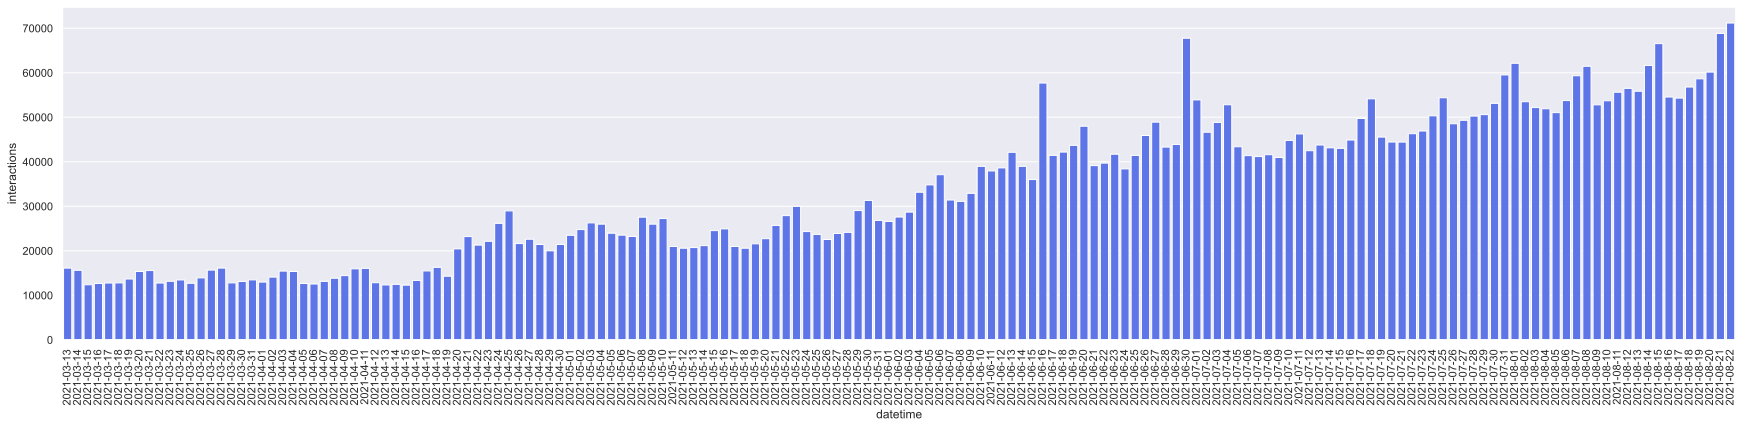

In [46]:
daily_iters = interactions.groupby(Columns.Datetime)[Columns.Datetime].agg("count")
daily_iters.name = "interactions"

sns.set_theme(rc={'figure.figsize':(30, 6)})
ax = sns.barplot(daily_iters, color='#4766ff')
plt.xticks(rotation=90);

По графику можно проверить недельную сезонность. Тестовое окно в 7 дней охватывает все дни недели. Здесь используется один train/test split. Отдельной валидации для подбора параметров пока нет.


In [47]:
train = interactions[
    (interactions['datetime'] < max_date - pd.Timedelta(days=7))
    & (interactions['datetime'] > max_date - pd.Timedelta(days=37))
]
test = interactions[(interactions['datetime'] >= max_date - pd.Timedelta(days=7))]

print(f"train: {train.shape}")
print(f"test: {test.shape}")

train: (1528877, 5)
test: (490982, 5)


In [48]:
# только горячие юзеры в тесте
test_hot = test[test['user_id'].isin(train['user_id'].unique())]
print(f"test hot: {test_hot.shape}")

test hot: (312789, 5)


## Факторизационные модели в RecTools и implicit

У моделей общая схема предсказания $\hat r_{ui}=p_u^\top q_i$, но разные функции потерь. Сравним размеры пространства `factors` из `N_FACTORS`

### Датасет и параметры

In [49]:
dataset = Dataset.construct(
    interactions_df=train,
    user_features_df=None,
    item_features_df=None,
)

In [50]:
K_RECOS = 10
RANDOM_STATE = 32
NUM_THREADS = 16
N_FACTORS = [4, 16, 32]

### PureSVD в RecTools

In [51]:
models = {}

for factors in N_FACTORS:
  models[f"PureSVD_{factors}"] = PureSVDModel(factors=factors)

In [52]:
models

{'PureSVD_4': <rectools.models.pure_svd.PureSVDModel at 0x158b456a0>,
 'PureSVD_16': <rectools.models.pure_svd.PureSVDModel at 0x326854910>,
 'PureSVD_32': <rectools.models.pure_svd.PureSVDModel at 0x326854690>}

### iALS в RecTools

iALS приближает бинарные предпочтения с учётом уверенности и регуляризации. Чередование обновлений уже реализовано в `implicit`; `ImplicitALSWrapperModel` адаптирует модель для `rectools.Dataset`.

`factors` определяет размер векторов, `regularization` — силу L2-регуляризации, `iterations` — число итераций ALS. Параметр `alpha` масштабирует входные веса. Конвенция `implicit` отличается от учебной формулы $c=1+\alpha r$: для положительных сохранённых элементов используются масштабированные входные веса как уверенности, а для отсутствующих пар — 1. Поэтому одинаковые значения параметров и исходная матрица не гарантируют совпадения с реализацией выше.

In [53]:
for factors in N_FACTORS:
  models[f"ALS_factors_{factors}"] = ImplicitALSWrapperModel(
      model=AlternatingLeastSquares(
          factors=factors,
          random_state=RANDOM_STATE,
          num_threads=NUM_THREADS
      )
  )

In [54]:
models

{'PureSVD_4': <rectools.models.pure_svd.PureSVDModel at 0x158b456a0>,
 'PureSVD_16': <rectools.models.pure_svd.PureSVDModel at 0x326854910>,
 'PureSVD_32': <rectools.models.pure_svd.PureSVDModel at 0x326854690>,
 'ALS_factors_4': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x158b45940>,
 'ALS_factors_16': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x326854550>,
 'ALS_factors_32': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x326854a50>}

### BPR-MF в RecTools

Используем ту же факторную модель с BPR-loss, что и в ручном разделе. `ImplicitBPRWrapperModel` адаптирует `implicit.BayesianPersonalizedRanking` к `rectools.Dataset`.

В отличие от учебного полного перебора троек, библиотека использует стохастические обновления и сэмплирование. Также учитывается смещение объекта. Величины весов взаимодействий игнорируются. При многопоточном обучении фиксированный `random_state` не гарантирует одинакового результата.

In [55]:
for factors in N_FACTORS:
  models[f"BPR_factors_{factors}"] = ImplicitBPRWrapperModel(
      model=BayesianPersonalizedRanking(
          factors=factors,
          random_state=RANDOM_STATE,
          num_threads=NUM_THREADS
      )
  )

In [56]:
models

{'PureSVD_4': <rectools.models.pure_svd.PureSVDModel at 0x158b456a0>,
 'PureSVD_16': <rectools.models.pure_svd.PureSVDModel at 0x326854910>,
 'PureSVD_32': <rectools.models.pure_svd.PureSVDModel at 0x326854690>,
 'ALS_factors_4': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x158b45940>,
 'ALS_factors_16': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x326854550>,
 'ALS_factors_32': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x326854a50>,
 'BPR_factors_4': <rectools.models.implicit_bpr.ImplicitBPRWrapperModel at 0x158b45be0>,
 'BPR_factors_16': <rectools.models.implicit_bpr.ImplicitBPRWrapperModel at 0x326854e10>,
 'BPR_factors_32': <rectools.models.implicit_bpr.ImplicitBPRWrapperModel at 0x326855090>}

### Logistic MF в implicit

Используем библиотечную логистическую факторизацию. В отличие от учебного примера, реализация `implicit` добавляет смещения, использует веса взаимодействий и сэмплирование отрицательных пар. `neg_prop` управляет числом отрицательных примеров.

В используемой версии RecTools готовой обёртки для Logistic MF нет, поэтому вызываем модель напрямую из `implicit`: передаём CSR-матрицу и внутренние ID, а перед расчётом метрик возвращаем исходные ID через маппинги Dataset. Для ранжирования достаточно скоров: сигмоида монотонна и не меняет порядок.

In [57]:
test_hot[Columns.User].unique()

array([200197,  73446, 890735, ..., 196036, 623792, 442859],
      shape=(101696,))

In [58]:
dataset.user_id_map.convert_to_internal(test_hot[Columns.User].unique())

array([309131,  27457, 287306, ..., 268905, 331232,  81075],
      shape=(101696,))

In [59]:
ui_csr = dataset.interactions.get_user_item_matrix()
test_users_lmf = dataset.user_id_map.convert_to_internal(test_hot[Columns.User].unique())

In [60]:
for factors in N_FACTORS:
  models[f"LMF_factors_{factors}"] = LogisticMatrixFactorization(
    factors=factors,
    random_state=RANDOM_STATE,
    num_threads=NUM_THREADS
  )
  models[f"LMF_factors_{factors}"].fit(ui_csr)

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

In [61]:
models

{'PureSVD_4': <rectools.models.pure_svd.PureSVDModel at 0x158b456a0>,
 'PureSVD_16': <rectools.models.pure_svd.PureSVDModel at 0x326854910>,
 'PureSVD_32': <rectools.models.pure_svd.PureSVDModel at 0x326854690>,
 'ALS_factors_4': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x158b45940>,
 'ALS_factors_16': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x326854550>,
 'ALS_factors_32': <rectools.models.implicit_als.ImplicitALSWrapperModel at 0x326854a50>,
 'BPR_factors_4': <rectools.models.implicit_bpr.ImplicitBPRWrapperModel at 0x158b45be0>,
 'BPR_factors_16': <rectools.models.implicit_bpr.ImplicitBPRWrapperModel at 0x326854e10>,
 'BPR_factors_32': <rectools.models.implicit_bpr.ImplicitBPRWrapperModel at 0x326855090>,
 'LMF_factors_4': <implicit.cpu.lmf.LogisticMatrixFactorization at 0x158b45d30>,
 'LMF_factors_16': <implicit.cpu.lmf.LogisticMatrixFactorization at 0x3268565d0>,
 'LMF_factors_32': <implicit.cpu.lmf.LogisticMatrixFactorization at 0x326856fd0>}

## Сравнение моделей

In [62]:
metrics_name = {
    "precision": Precision,
    "recall": Recall,
    "ndcg": NDCG,
    "serendipity": Serendipity,
    "novelty": MeanInvUserFreq,
}
K = [3, 5, 10]


metrics = {}
for metric_name, metric in metrics_name.items():
    for k in K:
        metrics[f'{metric_name}@{k}'] = metric(k=k)
metrics

{'precision@3': Precision(k=3, debias_config=None, r_precision=False),
 'precision@5': Precision(k=5, debias_config=None, r_precision=False),
 'precision@10': Precision(k=10, debias_config=None, r_precision=False),
 'recall@3': Recall(k=3, debias_config=None),
 'recall@5': Recall(k=5, debias_config=None),
 'recall@10': Recall(k=10, debias_config=None),
 'ndcg@3': NDCG(k=3, debias_config=None, log_base=2, divide_by_achievable=False),
 'ndcg@5': NDCG(k=5, debias_config=None, log_base=2, divide_by_achievable=False),
 'ndcg@10': NDCG(k=10, debias_config=None, log_base=2, divide_by_achievable=False),
 'serendipity@3': Serendipity(k=3),
 'serendipity@5': Serendipity(k=5),
 'serendipity@10': Serendipity(k=10),
 'novelty@3': MeanInvUserFreq(k=3),
 'novelty@5': MeanInvUserFreq(k=5),
 'novelty@10': MeanInvUserFreq(k=10)}

In [63]:
items = pd.read_csv("./data_original/items.csv")

In [64]:
test_user = 73446
(
    train[train[Columns.User] == test_user]
    .merge(items[["item_id", "title"]], on="item_id")
    .sort_values(by="datetime", ascending=False)
)[:15]

,user_id,item_id,datetime,total_dur,weight,title
20,73446,10761,2021-08-13,5554,90.0,Моана
32,73446,16166,2021-08-13,5578,89.0,Зверополис
8,73446,14591,2021-08-13,4126,61.0,Вне/себя
19,73446,6402,2021-08-12,6644,100.0,Королевский Гамбит
25,73446,1399,2021-08-12,314,4.0,Молодость
47,73446,1132,2021-08-12,5810,96.0,Крёстная мама
13,73446,5411,2021-08-12,5036,90.0,Монстры на каникулах 3: Море зовёт
12,73446,2220,2021-08-12,5196,96.0,С днём смерти
11,73446,14899,2021-08-12,321,6.0,Убийство онлайн
9,73446,12893,2021-08-12,377,6.0,Сентенция


In [65]:
catalog = train[Columns.Item].unique()

results = []
for model_name, model in models.items():
    if model_name not in {'LMF_factors_4', 'LMF_factors_16', 'LMF_factors_32'}:
        model_quality = {'model': model_name}
        
        fit_start_time = time.perf_counter()
        model.fit(dataset)
        training_time = time.perf_counter() - fit_start_time
      
        recos = model.recommend(
            users=test_hot[Columns.User].unique(),
            dataset=dataset,
            k=K_RECOS,
            filter_viewed=True, # What for this parameter is needed?
        )

        print(f"{model_name} [train = {training_time:.2f} с]:")
        print(
            recos[recos[Columns.User] == test_user][["user_id", "rank", "item_id"]]
            .merge(items[["item_id", "title"]], on="item_id")
        )
        print('-' * 100)
        
        metric_values = calc_metrics(metrics, recos, test_hot, train, catalog=catalog)
        
        model_quality.update(metric_values)
        results.append(model_quality)

PureSVD_4 [train = 0.19 с]:
   user_id  rank  item_id                title
0    73446     1    13865             Девятаев
1    73446     2     9728    Гнев человеческий
2    73446     3     3784       Маленький воин
3    73446     4     4495             Пальмира
4    73446     5     8636           Белый снег
5    73446     6      142                 Маша
6    73446     7     7793         Радиовспышка
7    73446     8     6809                Дуров
8    73446     9     5434   История семьи Блум
9    73446    10     4457  2067: Петля времени
----------------------------------------------------------------------------------------------------
PureSVD_16 [train = 0.46 с]:
   user_id  rank  item_id                   title
0    73446     1     3182  Ральф против Интернета
1    73446     2    16270              Тайна Коко
2    73446     3     7582      Холодное сердце II
3    73446     4    15266     Корпорация монстров
4    73446     5     2954                 Миньоны
5    73446     6    12965

In [66]:
for factors in N_FACTORS:
  reco_LMF = []
  for user_id in tqdm(test_users_lmf):
      res = models[f"LMF_factors_{factors}"].recommend(user_id, ui_csr[user_id], N=K_RECOS, filter_already_liked_items=True)
      user_ids = [user_id]*K_RECOS
      item_ids = res[0]
      scores = res[1]
      for rank, (user_id, item_id, score) in enumerate(zip(user_ids, item_ids, scores), start=1):
          reco_LMF.append({
              'user_id': user_id,
              'item_id': item_id,
              'score': score,
              'rank': rank
          })

  df_recos = pd.DataFrame(reco_LMF)
  df_recos['item_id'] = pd.Series(dataset.item_id_map.convert_to_external(df_recos.item_id))
  df_recos['user_id'] = pd.Series(dataset.user_id_map.convert_to_external(df_recos.user_id))

  print(f"LMF_factors_{factors}:")
  print(df_recos[df_recos['user_id'] == test_user].merge(items[["item_id", "title"]], on="item_id"))

  metric_values = calc_metrics(metrics, df_recos, test_hot, train, catalog=catalog)
  model_quality = {'model': f"LMF_factors_{factors}"}
  model_quality.update(metric_values)
  results.append(model_quality)

100%|███████████████████████████████████████████████████████████████████████████████████████████| 101696/101696 [00:05<00:00, 18157.23it/s]


LMF_factors_4:
   user_id  item_id      score  rank                          title
0    73446     8540  10.676715     1                Ловушка времени
1    73446     8694   9.755905     2  Чужие против Хищника: Реквием
2    73446    14213   9.693359     3                      NEED ХЕЛП
3    73446     3293   9.688688     4              Жених для дурочки
4    73446     4571   9.539231     5                        Бэбибум
5    73446    12857   9.461399     6                         Викинг
6    73446     4191   9.431371     7                        Застава
7    73446    12537   9.336585     8                           Поли
8    73446     8222   9.322199     9            Афера по-итальянски
9    73446    10077   9.308218    10              Что скрывает вода


100%|███████████████████████████████████████████████████████████████████████████████████████████| 101696/101696 [00:07<00:00, 13765.49it/s]


LMF_factors_16:
   user_id  item_id      score  rank                                  title
0    73446      475  18.011415     1                                 Ученик
1    73446     6686  17.992355     2                 Планета обезьян: Война
2    73446     5635  16.736788     3                         Другая женщина
3    73446    13763  15.506078     4                               Братство
4    73446    15422  14.894363     5                         Астрал. Онлайн
5    73446     9343  14.226486     6                       Ассистент звезды
6    73446     4610  14.159260     7                    Мужчина с гарантией
7    73446     7969  14.097643     8  Человек, который познал бесконечность
8    73446    16197  14.039829     9                                  Поиск
9    73446     4946  14.039419    10                             Два сердца


100%|███████████████████████████████████████████████████████████████████████████████████████████| 101696/101696 [00:07<00:00, 12929.21it/s]


LMF_factors_32:
   user_id  item_id      score  rank                               title
0    73446     8134  24.303513     1                          Большой Ух
1    73446    12846  22.291941     2                            Люди Икс
2    73446     5650  21.957766     3  Эйс Вентура 2: Когда зовет природа
3    73446    13598  20.755531     4                         Нация убийц
4    73446    13021  20.534172     5               Между нами, девочками
5    73446     3182  20.283733     6              Ральф против Интернета
6    73446     3834  19.907824     7                               Ральф
7    73446    12259  19.080269     8                          Неуязвимый
8    73446    16087  19.032433     9      Убийство в Восточном экспрессе
9    73446     8585  18.966181    10                           Дитя тьмы


### Сводная таблица

Сравним модели при одинаковом K и посмотрим, как влияет число факторов. Больше факторов — больше ёмкость и стоимость вычислений, но не гарантия лучшего качества.

В текущем коде время обучения печатается только для моделей RecTools и не попадает в таблицу.

In [67]:
df_quality = pd.DataFrame(results).T
df_quality.columns = df_quality.iloc[0]
df_quality.drop("model", inplace=True)

In [68]:
df_quality.style.highlight_max(color='lightgreen', axis=1)

model,PureSVD_4,PureSVD_16,PureSVD_32,ALS_factors_4,ALS_factors_16,ALS_factors_32,BPR_factors_4,BPR_factors_16,BPR_factors_32,LMF_factors_4,LMF_factors_16,LMF_factors_32
precision@3,0.042752,0.027176,0.025042,0.045620,0.043951,0.041824,0.020525,0.024681,0.026589,0.007981,0.006224,0.005323
precision@5,0.037457,0.024750,0.022349,0.038684,0.037132,0.036450,0.017865,0.021108,0.022054,0.007304,0.005735,0.004907
precision@10,0.026606,0.019008,0.017671,0.028508,0.029274,0.027839,0.014247,0.016538,0.016944,0.005803,0.005000,0.004276
recall@3,0.057444,0.033115,0.030133,0.062934,0.058356,0.056221,0.029989,0.034690,0.037043,0.012183,0.008202,0.006423
recall@5,0.083598,0.049891,0.043939,0.086501,0.080155,0.079856,0.042664,0.047946,0.049126,0.018242,0.012516,0.009800
recall@10,0.114579,0.073191,0.066481,0.121433,0.123050,0.116283,0.065504,0.072009,0.072685,0.027940,0.021434,0.016849
ndcg@3,0.045406,0.028111,0.025449,0.048299,0.046510,0.044262,0.021986,0.026085,0.028692,0.008177,0.006403,0.005551
ndcg@5,0.041045,0.026193,0.023474,0.042799,0.041081,0.039873,0.019747,0.023226,0.024981,0.007660,0.006016,0.005198
ndcg@10,0.032194,0.021695,0.019826,0.034178,0.034268,0.032662,0.016561,0.019305,0.020387,0.006489,0.005408,0.004656
novelty@3,4.055495,6.089701,6.717879,4.869785,5.418368,5.987647,8.693492,8.882625,9.063191,9.384104,8.991744,8.983274


# Быстрый поиск рекомендаций: ANN

Получив векторы, нужно найти объекты с максимальным $p_u^\top q_i$. Точный поиск оценивает все объекты каталога для каждого пользователя. **ANN (Approximate Nearest Neighbor)** использует индекс, чтобы искать быстрее, допуская пропуски части точного top-K.

Здесь решаем **Maximum Inner Product Search (MIPS)** — поиск по максимальному скалярному произведению. Он отличается от cosine-поиска: длины векторов влияют на результат.

## Получаем векторы ALS

In [69]:
Columns.Datetime = "datetime"
train[Columns.Weight] = 1 # for simplicity
dataset = Dataset.construct(train)
test_users = test_hot[Columns.User].unique()

In [70]:
%%time
model = ImplicitALSWrapperModel(
    AlternatingLeastSquares(
        factors=32,
        iterations=10,
        num_threads=NUM_THREADS,
        random_state=RANDOM_STATE
    )
)
model.fit(dataset)

CPU times: user 4.75 s, sys: 52.3 ms, total: 4.81 s
Wall time: 4.81 s


In [71]:
user_factors, item_factors = model.get_vectors()
user_factors.shape, item_factors.shape

((396136, 32), (9992, 32))

## Точный поиск: сравниваем реализации

Сначала сравним выдачу через RecTools, напрямую через `implicit` и ручное умножение матриц батчами. Все варианты должны использовать одни векторы, пользователей и правила фильтрации. Здесь просмотренные объекты **не исключаются**.

### Выдача через RecTools

In [72]:
%%time
reco_rectools = model.recommend(
    users=test_users,
    dataset=dataset,
    k=K_RECOS,
    filter_viewed=False,
)

CPU times: user 1.42 s, sys: 79 ms, total: 1.5 s
Wall time: 1.49 s


### Выдача через implicit

Прямой вызов работает с внутренними ID

In [73]:
implicit_model = model.model
test_users_internal = dataset.user_id_map.convert_to_internal(test_users)
ui_csr = dataset.interactions.get_user_item_matrix()

In [74]:
%%time
item_ids, scores = implicit_model.recommend(
    test_users_internal,
    ui_csr[test_users_internal],
    N=K_RECOS,
    filter_already_liked_items=False,
)

CPU times: user 853 ms, sys: 96.9 ms, total: 950 ms
Wall time: 949 ms


### Точный поиск

Для всех пользователей вычисляем $S = PQ^\top$. `argpartition` выбирает кандидатов top-K без полной сортировки каталога, затем сортируем только выбранные объекты.

In [75]:
%%time
batch_scores = user_factors @ item_factors.T
batch_unsorted_reco_positions = batch_scores.argpartition(-K_RECOS, axis=1)[:, -K_RECOS:]

CPU times: user 25.2 s, sys: 14.5 s, total: 39.7 s
Wall time: 1min 55s


Нужно жуткое количество памяти (44 gb в пике) на хранение матриц и их перемножение. Из-за сжатия RAM и сброса на диск очень медленно

In [78]:
batch_scores.shape, batch_unsorted_reco_positions.shape

((396136, 9992), (396136, 10))

In [79]:
import gc
del batch_scores, batch_unsorted_reco_positions
gc.collect()

0

### Точный поиск батчами
Батчи ограничивают память, но каждый пользователь по-прежнему сравнивается со всеми объектами

In [220]:
# функция понадобится также дальше
def batch_knn_recs(k_recs: int = 10, batch_size: int = 256) -> np.array:
    reco_by_batch = []
    n_batches = len(test_users) // batch_size + 1
    
    for i_batch in tqdm(range(n_batches)):
        batch_users_ids = test_users_internal[i_batch * batch_size : (i_batch + 1) * batch_size]
        batch_users_factors = user_factors[batch_users_ids]
        batch_scores = batch_users_factors @ item_factors.T
        batch_unsorted_reco_positions = batch_scores.argpartition(-k_recs, axis=1)[:, -k_recs:]
        batch_unsorted_reco_scores = np.take_along_axis(batch_scores, batch_unsorted_reco_positions, axis=1)
        batch_recs = np.take_along_axis(
                batch_unsorted_reco_positions, batch_unsorted_reco_scores.argsort()[:, ::-1], axis=1
            )
        reco_by_batch.append(batch_recs)
    
    reco_by_batch = np.vstack(reco_by_batch)
    return reco_by_batch

In [221]:
%%time
reco_by_batch = batch_knn_recs(K_RECOS)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 398/398 [00:06<00:00, 60.70it/s]

CPU times: user 5.99 s, sys: 560 ms, total: 6.55 s
Wall time: 6.56 s


## Приближённый поиск: HNSW

**HNSW (Hierarchical Navigable Small World)** строит многоуровневый граф объектов: верхние уровни помогают быстро перейти в нужную область, нижние уточняют соседей. В индекс помещаем векторы объектов, запросами служат векторы пользователей.

В `hnswlib` режим `space="ip"` использует расстояние $1-p_u^\top q_i$: меньшему расстоянию соответствует больший скор.

Несколько важных параметров:
- `max_elements` — вместимость индекса, то есть максимальное число добавляемых объектов.
- `M` — параметр числа связей между вершинами графа. Увеличение обычно улучшает поиск, но требует больше памяти и времени построения.
- `ef_construction` — ширина поиска кандидатов при построении графа. Увеличение замедляет построение, но может улучшить качество связей.
- `ef` — ширина поиска кандидатов при запросе. Увеличение обычно повышает Recall и время запроса. Задаётся через `index.set_ef(...)`. Можно менять после заполнения индекса без перестроения. Используем ef ≥ K.
- `K` — число возвращаемых объектов. В отличие от него, ef управляет тщательностью поиска, а не длиной результата.

<div style='display: flex; gap: 20px;'>
    <div><img src="images/practice-3/hnsw-layers.jpg"></div>
    <div><img src="images/practice-3/hnsw-search.jpg"></div>
</div>

In [222]:
# pip install hnswlib

In [223]:
import hnswlib

In [224]:
def create_index(
    space: str,
    dim: int,
    max_elements: int,
    M: int,
    ef_construction: int,
    random_seed: int
) -> hnswlib.Index:

    hnswlib_index = hnswlib.Index(
        space=space,
        dim=dim
    )
    hnswlib_index.init_index(
        max_elements=max_elements,
        M=M,
        ef_construction=ef_construction,
        random_seed=random_seed,
    )
    return hnswlib_index

Создадим несколько индексов для сравнения

In [225]:
%%time
configs = [
    {"M": 16, "ef_construction": 100, "ef": 10},
    {"M": 16, "ef_construction": 100, "ef": 100},
    {"M": 16, "ef_construction": 100, "ef": 500},
    {"M": 32, "ef_construction": 500, "ef": 10},
    {"M": 32, "ef_construction": 500, "ef": 100},
    {"M": 32, "ef_construction": 500, "ef": 500},
]

indexes = {}

for config in configs:
    index = create_index(
        space='ip',
        dim=model.model.factors,
        max_elements=item_factors.shape[0],
        M=config['M'],
        ef_construction=config['ef_construction'],
        random_seed=42,
    )
    index.set_ef(config["ef"])

    indexes[f'index_{config['M']}_{config['ef_construction']}_{config['ef']}'] = index

indexes

CPU times: user 1.29 ms, sys: 2.22 ms, total: 3.51 ms
Wall time: 3.61 ms


{'index_16_100_10': <hnswlib.Index(space='ip', dim=32)>,
 'index_16_100_100': <hnswlib.Index(space='ip', dim=32)>,
 'index_16_100_500': <hnswlib.Index(space='ip', dim=32)>,
 'index_32_500_10': <hnswlib.Index(space='ip', dim=32)>,
 'index_32_500_100': <hnswlib.Index(space='ip', dim=32)>,
 'index_32_500_500': <hnswlib.Index(space='ip', dim=32)>}

In [226]:
item_factors.shape

(9992, 32)

In [227]:
%%time
for _, index in indexes.items():
    index.add_items(item_factors)

CPU times: user 8.05 s, sys: 1.72 s, total: 9.77 s
Wall time: 1.34 s


## Качество рекомендаций и точность поиска

RecTools возвращает исходные ID, а ручной поиск и HNSW — внутренние индексы. Перед сравнением приведём их к одному формату.

MAP по тестовым взаимодействиям измеряет качество рекомендаций. Отдельно полезно измерить совпадение ANN с точным top-K:

$$
Recall_{ANN}@K=\frac{1}{|\mathcal U|}\sum_{u\in\mathcal U}
\frac{|A_u^K\cap E_u^K|}{K}
$$

$A_u^K$ — приближённая выдача, $E_u^K$ — точная.

In [228]:
def calc_map(reco, k):
    global test_hot, test_users_internal
    reco_df = pd.DataFrame(
        {
            Columns.User: np.repeat(test_users, k),
            Columns.Item: dataset.item_id_map.convert_to_external(np.array(reco).ravel()),
            Columns.Rank: np.tile(np.arange(k) + 1, len(test_users)),
        }
    )
    metric = MAP(k=k).calc(reco_df, test_hot)
    return metric

In [229]:
def calc_ann_recall(exact_reco, ann_reco, k):
    exact_reco = np.asarray(exact_reco)
    ann_reco = np.asarray(ann_reco)
    return float(np.mean([
        np.intersect1d(exact[:k], approximate[:k]).size / k
        for exact, approximate in zip(exact_reco, ann_reco)
    ]))

Сравнивать будем батчевые точные рекоммендации и ANN рекомендации, потому что нужны внутренние id 

In [230]:
# декоратор для замеров батчевых рекомендаций
def timeit(function):
    def inner(*args, **kwargs):
        start = time.perf_counter()
        result = function(*args, **kwargs)
        ellapsed = time.perf_counter() - start
        return (ellapsed, result)
    return inner


batch_knn_recs = timeit(batch_knn_recs)

Сравнение при `n_recs = 10`

In [231]:
n_recs = 10

In [232]:
_, reco_by_batch = batch_knn_recs(n_recs)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 398/398 [00:06<00:00, 61.84it/s]


In [234]:
results = []

# KNN рекомендации
results.append({
    'Name': 'batch-kNN',
    'Recall': 1.0,
    'MAP': calc_map(reco_by_batch, k=n_recs),
    'Time': 7.0
})

# ANN рекомендации
for name, index in indexes.items():
    test_user_factors = user_factors[test_users_internal]
    start = time.perf_counter()
    reco_ann, _ = index.knn_query(test_user_factors, n_recs)
    ellapsed = time.perf_counter() - start

    results.append({
        'Name': name,
        'Recall': calc_ann_recall(reco_by_batch, reco_ann, k=n_recs),
        'MAP': calc_map(reco_ann, k=n_recs),
        'Time': round(ellapsed, 3)
    })

pd.DataFrame(results)

,Name,Recall,MAP,Time
0,batch-kNN,1.000000,0.014900,7.000
1,index_16_100_10,0.793981,0.015301,0.151
2,index_16_100_100,0.916737,0.015002,0.355
3,index_16_100_500,0.924853,0.014855,1.278
4,index_32_500_10,0.820079,0.014989,0.174
5,index_32_500_100,0.917984,0.015024,0.440
6,index_32_500_500,0.931453,0.014885,1.627


На разных `n_recs` (10, 100, 500)

In [236]:
n_recs_values = [10, 100, 500]
test_user_factors = user_factors[test_users_internal]

results = {"batch-kNN": {"Name": "batch-kNN"}}
for name in indexes:
    results[name] = {"Name": name}

for n_recs in n_recs_values:
    elapsed, exact_reco = batch_knn_recs(k_recs=n_recs)

    results["batch-kNN"].update({
        f"recall@{n_recs}": 1.0,
        f"map@{n_recs}": calc_map(exact_reco, k=n_recs),
        f"time@{n_recs}": elapsed,
    })

    for name, index in indexes.items():
        start = time.perf_counter()
        ann_reco, _ = index.knn_query(
            test_user_factors,
            k=n_recs,
        )
        elapsed = time.perf_counter() - start

        results[name].update({
            f"recall@{n_recs}": calc_ann_recall(exact_reco, ann_reco, k=n_recs),
            f"map@{n_recs}": calc_map(ann_reco, k=n_recs),
            f"time@{n_recs}": elapsed,
        })

df_results = pd.DataFrame(results.values())
df_results.round(4)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████| 398/398 [00:08<00:00, 44.77it/s]


,Name,recall@10,map@10,time@10,recall@100,map@100,time@100,recall@500,map@500,time@500
0,batch-kNN,1.0000,0.0149,6.3887,1.0000,0.0225,6.8422,1.0000,0.0246,8.9776
1,index_16_100_10,0.7940,0.0153,0.1549,0.6732,0.0223,0.3670,0.3380,0.0235,1.5124
2,index_16_100_100,0.9167,0.0150,0.3545,0.6774,0.0224,0.4250,0.3356,0.0236,1.5252
3,index_16_100_500,0.9249,0.0149,1.2873,0.7152,0.0222,1.2860,0.3451,0.0235,1.5189
4,index_32_500_10,0.8201,0.0150,0.1758,0.7666,0.0223,0.4679,0.4924,0.0240,1.8201
5,index_32_500_100,0.9180,0.0150,0.4406,0.7623,0.0224,0.4602,0.4982,0.0240,1.7933
6,index_32_500_500,0.9315,0.0149,1.6382,0.8122,0.0223,1.7386,0.4888,0.0240,1.8092


HNSW позволяет ускорить выдачу за счёт приближённого поиска. Его параметры управляют компромиссом между скоростью и точностью. При этом расхождение с точным top-K не обязательно приводит к сопоставимому падению качества рекомендаций, поэтому оценивать нужно и точность поиска, и метрики на тестовых взаимодействиях.